# Context-Aware Chinese-English MT — Midterm Baseline (Colab)

- **Notebook Overview:** Downloads Chinese-English parallel sentence pairs, trains two independent sentence-only baseline models, evaluates both using corpus-level SacreBLEU on the same test set, and exports charts and predictions.

- **User Instructions:** Change runtime type to T4 GPU and run all cells in order. (Copying results to Google Drive cells are optional.)

- **Limitiations:** The TED dataset has not been verified for document/talk IDs. The current random sentence-pair split is suitable only for preliminary midterm baselines and should not be used to claim context-aware results. BLEU improvements are not guaranteed and conclusions will be based on the actual experimental results.


## 0. Configuration / GPU

In [ ]:
import os, random, torch
from pathlib import Path
SEED = 42
SAMPLE_SIZE = 5000  # first real run; use 2000 for smoke test or 10000 for larger run
MAX_READ_LINES = 40000
EPOCHS = 1
TRAIN_BATCH_SIZE = 8
EVAL_BATCH_SIZE = 8
GRAD_ACCUM = 2
MODEL_NAME = "Helsinki-NLP/opus-mt-zh-en"
ROOT = Path('/content/context_mt_solo')
DATA = ROOT / 'data'
DATA.mkdir(parents=True, exist_ok=True)
print('GPU available:', torch.cuda.is_available())
print('Device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
assert torch.cuda.is_available(), 'Please select a GPU runtime in Colab.'


GPU available: True
Device: Tesla T4


## 1. Install dependencies

In [ ]:
%pip -q install "transformers>=4.45,<5" "datasets>=3,<4" "accelerate>=1,<2" sentencepiece sacrebleu pandas scikit-learn matplotlib tqdm

import torch, transformers
print('torch:', torch.__version__, 'transformers:', transformers.__version__)
print('GPU:', torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 105.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 44.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 50.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 123.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 14.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 req

## 2. Download parallel TED Chinese–English text

In [ ]:
from pathlib import Path
from urllib.request import urlretrieve
DATA = Path('/content/context_mt/data'); DATA.mkdir(parents=True, exist_ok=True)
BASE = 'https://raw.githubusercontent.com/foreyes/ted-parallel-corpus-Chinese-English/master/data/'
for name in ['ch_res.txt', 'en_res.txt']:
    path = DATA / name
    if not path.exists():
        urlretrieve(BASE + name, path)
    print(name, path.stat().st_size, 'bytes')

ch_res.txt 11278055 bytes
en_res.txt 10118746 bytes


## 3. Clean / inspect aligned pairs

In [ ]:
import pandas as pd, re, itertools
raw=[]
with open(DATA/'ch_res.txt', encoding='utf8') as zh_f, open(DATA/'en_res.txt', encoding='utf8') as en_f:
    for idx, (zh, en) in enumerate(itertools.islice(itertools.zip_longest(zh_f, en_f), MAX_READ_LINES)):
        if zh is None or en is None: raise ValueError('Unequal number of lines')
        zh = re.sub(r'\s+', '', zh.strip())
        en = re.sub(r'\s+', ' ', en.strip())
        en = re.sub(r'\s+([.,!?;:%])', r'\1', en)
        en = re.sub(r"\b([A-Za-z]+) ' (s|t|re|ve|ll|d|m)\b", r"\1'\2", en)
        if 3 <= len(zh) <= 180 and 3 <= len(en) <= 350:
            raw.append({'chinese': zh, 'english': en, 'source_line': idx})
# Create dataframe
df = pd.DataFrame(raw)

# Remove numeric sentence IDs from Chinese and English
def remove_line_id(text):
    return re.sub(r'^\s*\d+\s*', '', str(text)).strip()

df["chinese"] = df["chinese"].apply(remove_line_id)
df["english"] = df["english"].apply(remove_line_id)

# Remove empty rows after cleaning
df = df[
    (df["chinese"] != "") &
    (df["english"] != "")
]

# Remove duplicates AFTER cleaning
df = df.drop_duplicates(['chinese', 'english'])
df = df.drop_duplicates('chinese')

print("Example cleaned sentence pairs:")
display(df[["chinese", "english"]].head(10))
assert len(df)>=100, 'Too few usable pairs; check download and filters'
df = df.sample(n=min(SAMPLE_SIZE,len(df)), random_state=42).reset_index(drop=True)
print('Clean pairs:', len(df)); display(df.head(10))
print('Selected sample size:', len(df))
assert len(df)>=100, 'Insufficient training data. Inspect the corpus URLs/filters.'


Example cleaned sentence pairs:


,chinese,english
0,（笑声）,(Laughter)
1,我妈妈就是这么黑。,That's just how black my mama was.
3,“给这个男孩取个最黑的名字吧！,"""Get this boy the blackest name possible."
4,书上是怎么说的？”,"What does the book say?"""
6,拉菲克是阿拉伯名字，但我们不是阿拉伯人。,"Rafiq is an Arabic name, but we are not Arabs."
7,我妈就是不想让我在21世纪好好坐飞机。,My mom just wanted me to have difficulty board...
10,瑟斯顿是英国姓氏，但我们不是英国人。,"Thurston is a British name, but we are not Bri..."
11,而瑟斯顿这个姓隔空致敬了美国奴隶制中世代延续的、没人性的经济制度。,"Shoutout to the multigenerational, dehumanizin..."
12,此外，瑟斯顿很适合星巴克员工。,"Also, Thurston makes for a great Starbucks name."
13,这真的推动了历史进程。,Really expedites the process.


Clean pairs: 5000


,chinese,english,source_line
0,然后他们就发现了这两身潜水服都是由同一个人，在同一时间买下的，时间是2014年10月7日，地...,So they were then able to tell that both wetsu...,18173
1,当我走进他们家庭的时候，我急需帮助。,"And when I came in, I had needs.",26621
2,帕特里斯和帕蒂几乎每天都整装待发，外出打猎地点是在他们家周围的森林里。,Patrice and Patee set out most days to go out ...,6945
3,当我们回顾整个历史所有那些在过去寻找灵丹妙药的人都有个共通点是他们都难逃一死。,When we look back through history at all those...,27659
4,一个是反对极端的个人主义文化。,One is to counter the culture of hyperindividu...,15269
5,你们觉得当巴士因为你坐轮椅而拒载你时，需要多少人可以阻挡一辆纽约的巴士呢？,How many people does it take to stop a bus in ...,8322
6,我想号召每个需要自己设计房屋的人。,I want to put every person that wants one in a...,21166
7,这个国家目前有两个当地政府声明它们要转变为不依赖石油的当地政府，莱斯特郡Leicesters...,There are now two local authorities in this co...,16381
8,太阳风暴是从太阳抛射出来的巨大的粒子云雾，它时刻提醒我们，我们生活在一颗活跃的恒星附近。,Solar storms are giant clouds of particles esc...,8360
9,我们和一个大型零售商协定，让他们在六个州的240个商店里卖我们的兰花。,And we're going to have high school kids growi...,27991


Selected sample size: 5000


## 4. Fixed 80/10/10 train/validation/test split

In [ ]:
from sklearn.model_selection import train_test_split
train_df, remainder = train_test_split(df, test_size=0.2, random_state=42)
val_df, test_df = train_test_split(remainder, test_size=0.5, random_state=42)
for name, part in [('train',train_df),('validation',val_df),('test',test_df)]:
    part.to_csv(DATA/f'{name}.csv',index=False)
    print(name, len(part))
assert not(set(train_df.chinese)&set(test_df.chinese))
assert not(set(train_df.chinese)&set(val_df.chinese))

train 4000
validation 500
test 500


## 5. Tokenization

In [ ]:
from datasets import Dataset
from transformers import AutoTokenizer, DataCollatorForSeq2Seq
MODEL_NAME = 'Helsinki-NLP/opus-mt-zh-en'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
def preprocess(batch):
    out = tokenizer(batch['chinese'],max_length=128,truncation=True)
    out['labels'] = tokenizer(text_target=batch['english'],max_length=128,truncation=True)['input_ids']
    return out
train_ds = Dataset.from_pandas(train_df[['chinese','english']],preserve_index=False)
val_ds = Dataset.from_pandas(val_df[['chinese','english']],preserve_index=False)
train_tok = train_ds.map(preprocess,batched=True,remove_columns=train_ds.column_names)
val_tok = val_ds.map(preprocess,batched=True,remove_columns=val_ds.column_names)
print('Tokenization complete')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

source.spm:   0%|          | 0.00/805k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/807k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Tokenization complete


## 6. Define training function

In [ ]:
import torch
import gc, random, numpy as np
from transformers import AutoModelForSeq2SeqLM, Seq2SeqTrainingArguments, Seq2SeqTrainer
ROOT = Path('/content/context_mt_solo'); ROOT.mkdir(exist_ok=True)
def train_one(name, lr):
    torch.manual_seed(42); np.random.seed(42); random.seed(42)
    model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
    run_dir = ROOT/name
    args = Seq2SeqTrainingArguments(
        output_dir=str(run_dir), learning_rate=lr,
        per_device_train_batch_size=TRAIN_BATCH_SIZE, per_device_eval_batch_size=EVAL_BATCH_SIZE,
        gradient_accumulation_steps=GRAD_ACCUM, num_train_epochs=EPOCHS,
        eval_strategy='epoch', save_strategy='epoch',
        save_total_limit=1, logging_steps=50,
        fp16=torch.cuda.is_available(), report_to='none', seed=42
    )
    trainer = Seq2SeqTrainer(
        model=model, args=args, train_dataset=train_tok, eval_dataset=val_tok,
        processing_class=tokenizer,
        data_collator=DataCollatorForSeq2Seq(tokenizer, model=model)
    )
    trainer.train()
    trainer.save_model(str(run_dir/'final'))
    tokenizer.save_pretrained(str(run_dir/'final'))
    pd.DataFrame(trainer.state.log_history).to_csv(run_dir/'history.csv',index=False)
    del trainer, model
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return run_dir

## 7. Run 1: learning rate 2e-5

In [ ]:
run1_dir = train_one('run1_lr2e-5', 2e-5)

pytorch_model.bin:   0%|          | 0.00/312M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/312M [00:00<?, ?B/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Epoch,Training Loss,Validation Loss
1,1.835600,1.843632


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3918: UserWarning: Moving the following attributes in the config to the generation config: {'max_length': 512, 'num_beams': 6, 'bad_words_ids': [[65000]]}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(


## 8. Run 2: learning rate 5e-5

In [ ]:
run2_dir = train_one('run2_lr5e-5', 5e-5)

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Epoch,Training Loss,Validation Loss
1,1.847000,1.849546


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3918: UserWarning: Moving the following attributes in the config to the generation config: {'max_length': 512, 'num_beams': 6, 'bad_words_ids': [[65000]]}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(


## 9. SacreBLEU on the same held-out test set

In [ ]:
import sacrebleu
from tqdm.auto import tqdm
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
def score_checkpoint(name, checkpoint):
    model=AutoModelForSeq2SeqLM.from_pretrained(str(checkpoint)).to(DEVICE)
    model.eval(); preds=[]
    srcs=test_df.chinese.tolist(); refs=test_df.english.tolist()
    for start in tqdm(range(0,len(srcs),16),desc=name):
        inputs=tokenizer(srcs[start:start+16],padding=True,truncation=True,
                         max_length=128,return_tensors='pt').to(DEVICE)
        with torch.inference_mode():
            outs=model.generate(**inputs,num_beams=4,max_new_tokens=128)
        preds.extend(tokenizer.batch_decode(outs,skip_special_tokens=True))
    assert len(preds)==len(refs)
    metric = sacrebleu.metrics.BLEU()
    bleu = metric.corpus_score(preds, [refs])

    test_df.assign(prediction=preds).to_csv(
      ROOT / f'{name}_predictions.csv', index=False
    )

    print(name, 'BLEU=', round(bleu.score, 2),
      'signature=', metric.get_signature())
    del model;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
    return bleu.score, str(metric.get_signature())

results=[]
for name, lr in [('run1_lr2e-5',2e-5),('run2_lr5e-5',5e-5)]:
    score,signature=score_checkpoint(name,ROOT/name/'final')
    results.append({'run':name,'learning_rate':lr,'SacreBLEU':score,'signature':signature})
scores=pd.DataFrame(results); display(scores)
scores.to_csv(ROOT/'bleu_results.csv',index=False)

run1_lr2e-5:   0%|          | 0/32 [00:00<?, ?it/s]

run1_lr2e-5 BLEU= 23.11 signature= nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0


run2_lr5e-5:   0%|          | 0/32 [00:00<?, ?it/s]

run2_lr5e-5 BLEU= 23.47 signature= nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0


,run,learning_rate,SacreBLEU,signature
0,run1_lr2e-5,0.00002,23.106467,nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|v...
1,run2_lr5e-5,0.00005,23.472216,nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|v...


## 10. Plots + samples

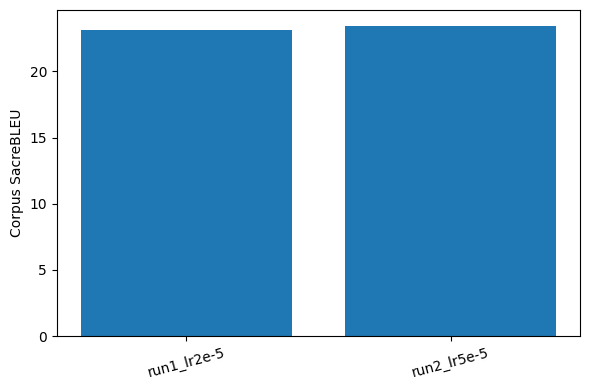

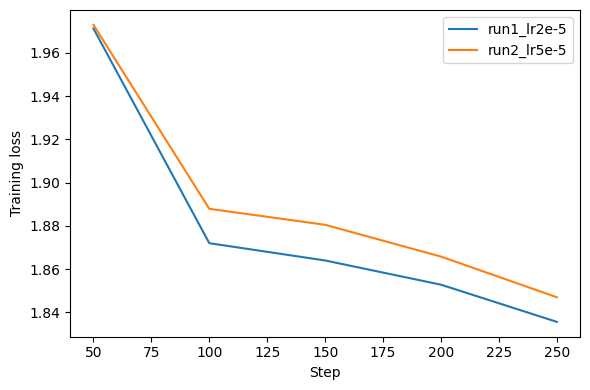

,chinese,english,run1_prediction,run2_prediction
0,唯有足够多的人相信民主，它才能发挥作用。,Democracy works only when enough of us believe...,It works only if there are enough people who b...,It works only if there are enough people who b...
1,这就是自我挫败的循环。,This is the cycle of self-defeat.,This is the cycle of self-frustration.,This is the cycle of self-frustration.
2,所以我很害怕，自己去参加面试的时候，会讲到一个不复存在的公司。,So I was afraid I'd go into an interview and s...,"So I'm scared that when I go to the interview,...","So I was scared, and when I went to the interv..."
3,还有一些强化方案，也就是人们正在努力研究的很多其他技术。,"Now, there are backstop options, which is othe...","And there's a lot of intensive programs, and t...","And there's a lot of intensive programs, and t..."
4,我们有自己的特点自己的步调任何一个了解拉各斯的人都可以告诉你赋予城市个性的往往是拉各斯的穷人。,"We have our own identity, our own rhythm, and ...","We have our own unique pace, and anyone who kn...","We have our own unique pace, and anyone who kn..."
5,年，我在加州拉霍亚的斯克里普斯研究所中的一间实验室开始探究这个问题，目标是要创造出活的有机体...,"In 1999, my lab at the Scripps Research Instit...","In the year, I began to explore this problem i...","In the year, I began to explore the problem in..."
6,也就意味着每年将近有1.3亿的婴儿出生。,That means that nearly 130 million babies are ...,It means that nearly 130 million babies are bo...,It means that nearly 130 million babies are bo...
7,"他们一起参观最现代化的汽车工厂，然后福特开玩笑地对鲁瑟说：""嘿，沃尔特，你怎么让这些机器人来...",They were touring one of the new modern factor...,They went to the most modern car factory toget...,They went to the most modern car factory toget...


In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4));plt.bar(scores['run'],scores['SacreBLEU'])
plt.ylabel('Corpus SacreBLEU');plt.xticks(rotation=15);plt.tight_layout()
plt.savefig(ROOT/'bleu_comparison.png',dpi=180);plt.show()
plt.figure(figsize=(6,4))
for name in scores['run']:
    history=pd.read_csv(ROOT/name/'history.csv')
    if 'loss' in history.columns:
        sub=history.dropna(subset=['loss'])
        plt.plot(sub['step'],sub['loss'],label=name)
plt.xlabel('Step');plt.ylabel('Training loss');plt.legend();plt.tight_layout()
plt.savefig(ROOT/'training_loss.png',dpi=180);plt.show()
a=pd.read_csv(ROOT/'run1_lr2e-5_predictions.csv')
b=pd.read_csv(ROOT/'run2_lr5e-5_predictions.csv')
examples=a[['chinese','english','prediction']].head(8).rename(columns={'prediction':'run1_prediction'}).copy()
examples['run2_prediction']=b['prediction'].head(8).to_numpy()
display(examples)
examples.to_csv(ROOT/'sample_translations.csv',index=False)

## 11. Package outputs into one ZIP

In [ ]:
import shutil
archive = shutil.make_archive('/content/context_mt_solo_results', 'zip', root_dir=str(ROOT))
print('ZIP:', archive)
print('Key files: bleu_results.csv, bleu_comparison.png, training_loss.png, sample_translations.csv')
from google.colab import files
files.download(archive)


ZIP: /content/context_mt_solo_results.zip
Key files: bleu_results.csv, bleu_comparison.png, training_loss.png, sample_translations.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Copy results to Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import shutil
DEST = Path('/content/drive/MyDrive/context_mt_solo_midterm')
shutil.copytree(ROOT, DEST, dirs_exist_ok=True)
print('Saved at:', DEST)


In [ ]:
from pathlib import Path

print("DATA path:", DATA)
print("Files:", list(DATA.iterdir()))

for name in ["train.csv", "validation.csv", "test.csv"]:
    path = DATA / name
    print(name, "Exists:", path.exists())

DATA path: /content/context_mt/data
Files: [PosixPath('/content/context_mt/data/ch_res.txt'), PosixPath('/content/context_mt/data/test.csv'), PosixPath('/content/context_mt/data/train.csv'), PosixPath('/content/context_mt/data/validation.csv'), PosixPath('/content/context_mt/data/en_res.txt')]
train.csv Exists: True
validation.csv Exists: True
test.csv Exists: True


In [ ]:
from google.colab import files

files.download(str(DATA / "train.csv"))
files.download(str(DATA / "validation.csv"))
files.download(str(DATA / "test.csv"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Midterm reporting checklist

- Implemented baseline: pretrained Helsinki-NLP/opus-mt-zh-en, **sentence-only** Chinese → English, fine-tuned with paired text.
- Two runs: identical data/split/epoch/seed, learning rate 2e-5 versus 5e-5.
- Evidence: actual training & validation logs, corpus SacreBLEU on same test split, 3–5 Chinese/reference/predicted examples.
- Dataset limitation: TED paired sentences here are **not validated conversation/document context**; do not claim context-aware results.
- Future: switch to properly segmented discourse data; compare no/correct/irrelevant/misleading context; account for truncation and leakage.
- State actual sample counts, BLEU score, metric signature, library versions, hardware, GitHub link and team role.

Sources: [TED corpus](https://github.com/foreyes/ted-parallel-corpus-Chinese-English), [OPUS-MT zh-en model](https://huggingface.co/Helsinki-NLP/opus-mt-zh-en), [SacreBLEU](https://github.com/mjpost/sacrebleu).
